# E. Tufte Slope Graphs contest 

So here is my entry for the slope Graph contest. (You can find the initial bounty description [here](http://www.edwardtufte.com/bboard/q-and-a-fetch-msg?msg_id=0003nk) )

## Installation

### Dependancies 

This script is written in Python and relies on Numpy, Pandas and Matplotlib.  
The easiest way to have a clean and robust install is to download one the great Scientific Python distribution, nameley : 

* [Anaconda](https://store.continuum.io/cshop/anaconda/)
* [Canopy](https://www.enthought.com/products/canopy/)
* [Python(x,y)](https://code.google.com/p/pythonxy/)

Everything you'll need is included. I personally use Anaconda from the guys at Continuum Analytics. All of them should work on Linux, Windows and Mac.  

### Download the sources

Go grab the sources at https://github.com/pascal-schetelat/Slope

- If you want slope to be available anywhere on your system : 

```bash
python setup.py install
```

- Else, just set the working directory where plotSlope.py is.


Then you are good to go. Import it in a Python interpreter (for instance Spyder, the Scientific python IDE bundled with Anaconda, or a jupyter notebook): 


```python
from plotSlope import slope
```    

## Usage 

Import : 

In [1]:
import pandas as pd
import os

In [2]:
from plotSlope import slope

Load data from file into a data frame : 

In [3]:
data1 = pd.read_csv(os.path.join('data','EU_GDP_2007_2013.csv'),index_col=0,na_values='-')
(data1/1000).head()

,2007,2008,2009,2010,2011,2012,2013
Austria,274.0198,282.7460,274.8182,286.1973,300.8913,310.1333,322.1904
Belgium,335.6100,346.1300,340.3980,354.3780,370.4364,381.7799,396.2738
Bulgaria,30.7724,35.4305,34.9328,36.0335,38.9899,NaN,NaN
Croatia,43.3804,47.7602,45.6661,45.8992,46.0216,46.7810,48.1752
Cyprus,15.9015,17.1571,16.8535,17.3336,17.9286,18.4096,19.1675


Plot it :

In [4]:

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties, findSystemFonts
import numpy as np
import pandas as pd
import os
import matplotlib.gridspec as gridspec

TypeError: 'numpy.float64' object cannot be interpreted as an integer

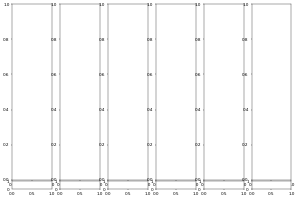

In [5]:
data = data1.copy()
kind='interval'
marker='%0.f'
color=None
title=''
font_family='GillSans'
font_size=12
width=12
height=8
ax=None
savename=None
dpi=150
wspace=None,

font = FontProperties(font_family)
font.set_size(font_size)
bx = None

df = data.copy()

cols = df.columns
df['__label__'] = df.index
df['__order__'] = range(len(df.index))

if kind == 'stack':
    f, axarr = plt.subplots(len(df), len(cols) - 1,
                            facecolor="w",
                            squeeze=False,
                            sharex=True)  #,sharey=True)
else:
    f = plt.figure(figsize=(width, height), dpi=30, facecolor="w")
    gs = gridspec.GridSpec(
        nrows=20,
        ncols=len(cols) - 1
    )  # the 20 rows are just there to provide enought space for the title
    axarr = []
    axarr_X = []

    for i in range(len(cols) - 1):
        axarr.append(plt.subplot(gs[:19, i]))
        axarr_X.append(plt.subplot(gs[19, i]))

axarr = np.array(axarr)
axarr_X = np.array(axarr_X)
renderer = f.canvas.get_renderer()
data_range = [data.min().min(), data.max().max()]
fh = f.get_figheight()
fw = f.get_figwidth()
fdpi = f.get_dpi()

nt = fh // (font.get_size() / 72) / 2
res = np.diff(data_range)[0] / nt * 2

if not hasattr(axarr, 'transpose'):
    axarr = [axarr]

for i in range((len(cols) - 1)):
    ax = axarr[i]

    axarr_X[i].yaxis.set_tick_params(width=0)
    axarr_X[i].xaxis.set_tick_params(width=0)
    """
    from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, HPacker
    # orange label
    obox1 = TextArea("orange - ", textprops=dict(color="k", size=15))
    obox2 = TextArea("5 ", textprops=dict(color="b", size=15))
    obox3 = TextArea(": ", textprops=dict(color="k", size=15))
    obox4 = TextArea("10 ", textprops=dict(color="r", size=15))

    orangebox = HPacker(children=[obox1, obox2, obox3, obox4],
                        align="center", pad=0, sep=5)
                """

    if kind == 'interval':
        labelsL = df.groupby(pd.cut(df[cols[i]], nt))['__label__'].agg(
            ', '.join).dropna()
        labelsR = df.groupby(pd.cut(df[cols[i + 1]], nt))['__label__'].agg(
            ', '.join).dropna()

        yPos_L = df.groupby(pd.cut(df[cols[i]],
                                   nt))[cols[i]].mean().dropna()
        yPos_R = df.groupby(pd.cut(df[cols[i + 1]],
                                   nt))[cols[i + 1]].mean().dropna()

        yMark_L = df.groupby(pd.cut(df[cols[i]],
                                    nt))[cols[i]].mean().dropna()
        yMark_R = df.groupby(pd.cut(df[cols[i + 1]],
                                    nt))[cols[i + 1]].mean().dropna()

        yPos_ = df[[cols[i], cols[i + 1]]]

    if kind == 'ordinal':

        yPos_L = df[[cols[i]]].rank(ascending=False).applymap(
            lambda el: round(el + 0.1))
        yPos_R = df[[cols[i + 1]]].rank(ascending=False).applymap(
            lambda el: round(el + 0.1))
        yMark_L = df.groupby(cols[i])[cols[i]].mean().dropna()
        yMark_R = df.groupby(cols[i + 1])[cols[i + 1]].mean().dropna()
        yMark_L.sort(ascending=False)
        yMark_R.sort(ascending=False)
        #print yMark_L

        labelsL = df.groupby(yPos_L[cols[i]].values)['__label__'].agg(
            ', '.join)
        labelsR = df.groupby(yPos_R[cols[i + 1]].values)['__label__'].agg(
            ', '.join)
        yPos_L.sort(cols[i], inplace=True)
        yPos_R.sort(cols[i + 1], inplace=True)

        yPos_ = yPos_L.join(yPos_R)  #.sort(cols[i],inplace=True)
#        if i == 1: 
#            #print yPos_.T
#            print labelsL
#            #yPos_   =  df[[cols[i],cols[i+1]]]
#

#        if kind=='stack' : 
#            
#            yPos_L = df[cols[i]].rank()
#            yPos_R = df[cols[i+1]].rank()
#            
#            labelsL = df.groupby(yPos_L)['__label__'].agg(', '.join) 
#            labelsR = df.groupby(yPos_R)['__label__'].agg(', '.join) 
#            
#            yPos_ = yPos_L.join(yPos_R)            
#            
#            yPos_L  =  labelsL.index.values
#            yPos_R  =  labelsR.index.values

    if kind == "stack":
        ax.plot([0, 1], [0, 1], color='k', alpha=0.4)
    else:
        #print yPos_
        lines = ax.plot(yPos_.T, color='k', alpha=0.4)
        ax.spines['bottom'].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')

        if kind == "ordinal":
            ax.set_ybound(lower=1, upper=len(yPos_))
        if kind == "interval":
            ax.set_ybound(lower=data.min().min(), upper=data.max().max())

            #ax.set_xbound(lower=0,upper=1)

        ax.set_xticklabels([])
        #print cols[i]
        axarr_X[i].set_yticks([1])
        axarr_X[i].set_xticklabels([])
        axarr_X[i].set_yticklabels([str(cols[i])], fontproperties=font)


        if marker:
            labelsL_str = [item[1] + (marker % item[0]).rjust(6)
                           for item in zip(yMark_L.values, labelsL.values)]
            labelsR_str = [(marker % item[0]).ljust(6) + item[1]
                           for item in zip(yMark_R.values, labelsR.values)]
            ylabelsL_str = map(lambda el: marker % el, yMark_L.values)
            ylabelsR_str = map(lambda el: marker % el, yMark_R.values)
        else:
            labelsL_str = labelsL.values
            labelsR_str = labelsR.values
            ylabelsL_str = map(lambda el: u'', yPos_L.values)
            ylabelsR_str = map(lambda el: u'', yPos_R.values)

        if i == 0:
            ax.set_yticks(yPos_L.values)
            ax.set_yticklabels(labelsL_str, fontproperties=font)
        elif marker:
            ax.set_yticks(yPos_L.values)
            ax.set_yticklabels([el for el in  ylabelsL_str],
                               fontproperties=font,
                               ha='right'
                               )  #ha='center')#,backgroundcolor='w')
        else:
            plt.setp(ax.get_yticklabels(), visible=False)
            wspace = 0

        if i == len(cols) - 2:
            bx = ax.twinx()

            bx.set_ybound(ax.get_ybound())
            bx.set_yticks(yPos_R.values)
            bx.set_yticklabels(labelsR_str, fontproperties=font)
            bx.yaxis.set_tick_params(width=0)

            bx_X = axarr_X[i].twinx()
            bx_X.set_xticklabels([])
            bx_X.set_yticks([1])
            bx_X.yaxis.set_tick_params(width=0)
            bx_X.set_yticklabels([str(cols[i + 1])], fontproperties=font)

        if kind == 'ordinal':
            ax.invert_yaxis()
            if bx:
                bx.invert_yaxis()

        if color:

            for tl in ax.yaxis.get_ticklabels():
                try:
                    for kw, c in color.items():

                        if kw in tl.get_text():
                            tl.set_color(c)

                except:
                    print('fail')
                    pass
            if bx:
                for tl in bx.yaxis.get_ticklabels():
                    try:
                        for kw, c in color.items():

                            if kw in tl.get_text():
                                tl.set_color(c)
                    except:
                        pass

        if color:
            for kw, c in color.items():
                for j, lab__ in enumerate(yPos_.index):
                    if kw in lab__:
                        lines[j].set_color(c)
                        lines[j].set_linewidth(2)
                        lines[j].set_alpha(0.6)

                        for kk, tic_pos in enumerate(
                            ax.yaxis.get_ticklocs()):

                            if yPos_.values[j][0] == tic_pos:

                                ax.yaxis.get_ticklabels()[kk].set_color(c)

        ax.yaxis.set_tick_params(width=0)
        ax.xaxis.set_tick_params(width=0)

        ax.xaxis.grid(False)

f.suptitle(title, x=0.5, y=0.02, fontproperties=font)
plt.tight_layout()

for ax in f.axes:
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

tw = ax.yaxis.get_text_widths(renderer)[0]
if wspace == 0:
    pass
else:
    #wspace = tw/dpi
    aw = ax.get_tightbbox(renderer).width
    wspace = tw / aw * 1.4

f.subplots_adjust(wspace=wspace)

if kind == "stack":
    f.subplots_adjust(wspace=wspace, hspace=0)
else:
    pass

if savename:
    f.savefig( savename, dpi=dpi)

return f

In [ ]:
labelsL = df.groupby(pd.cut(df[cols[i]], int(nt) ))['__label__'].agg(
            ', '.join).dropna()

In [ ]:
nt

In [ ]:
f = slope(data/1000,kind='interval',height= 12,width=20,font_size=12,dpi=150,savename='EU_interval.png',title = u'title')

In [ ]:
color  = {"France":'b','Germany':'r','Ireland':'chocolate','United Kingdom': 'purple'}
f = slope(data/1000, title = u'European GPD until 2010 and forecasts at market prices (billions of Euro) source : EUROSTAT',
          kind='interval',height= 12,width=22,font_size=15,
          savename='test.png',color=color,dpi=200) 

In [ ]:
f = slope(data/1000, title = u'European GPD until 2010 and forecasts at market prices (billions of Euro) source : EUROSTAT',
          kind='interval',height= 12,width=30,font_size=20,
          savename=None,color=color) 

## Other example : Random data 

In [ ]:
df = pd.DataFrame( np.random.normal(loc=np.ones(shape=[20,30])*np.arange(30)))
df.rename(columns = lambda el : str(el),index =lambda el : str(el),inplace=True) 

In [ ]:
f = slope(df.T,width =10,height= 8,kind='ordinal',savename=None,dpi=200,color={'10':'red','27':'blue'},marker=None) 